# AFDM: аффинное частотное мультиплексирование

OTFS (`otfs_sim`) разделяет лучи по задержке и доплеру, раскладывая кадр на **двумерную** решётку $M\times N$. AFDM (Bemani, Ksairi, Kountouris, 2021–2023) добивается того же в **одномерном** кадре из $N$ отсчётов, на **чирпах** с подобранным наклоном. Базис — дискретное аффинное преобразование Фурье (DAFT):
$$A=\Lambda_{c_2}\,F\,\Lambda_{c_1},\qquad \Lambda_c=\mathrm{diag}\big(e^{-j2\pi c\,n^2}\big),\qquad s=A^Hx,$$
$$s[n]=\frac1{\sqrt N}\sum_m x[m]\,e^{\,j2\pi\left(c_1n^2+c_2m^2+nm/N\right)} .$$
Это семейство с двумя параметрами:
- $c_1=c_2=0$ — DFT, то есть **OFDM**;
- $c_1=c_2=1/(2N)$ — преобразование Френеля, то есть **OCDM** (`ocdm_sim`);
- $c_1=\dfrac{2(\alpha_\max+\xi)+1}{2N}$ — **AFDM**: наклон чирпа подобран под максимальный доплер канала.

Луч с задержкой $l$ и доплером $\alpha$ (в бинах $f_s/N$) сдвигает символ в области DAFT на $(\alpha-2Nc_1l)\bmod N$. При $2Nc_1>2(\alpha_\max+\xi)$ блоки доплеров соседних задержек **не перекрываются**: каждый луч занимает свои отсчёты, канал разрежен, и детектор получает полное разнесение — как у OTFS, но без двумерной сетки и с одномерным пилотом.

Параметры кадра те же, что в `otfs_sim`: $N=1024$ отсчётов при $f_s=0.96$ МГц (бин доплера 937.5 Гц), 500 км/ч на 4 ГГц, 5 лучей.

1. Чирпы DAFT: OFDM, OCDM, AFDM · 2. Чирп-периодический префикс · 3. Канал в области DAFT · 4. BER: OFDM, OCDM, AFDM, OTFS на одном канале · 5. Встроенный пилот в одномерном кадре

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N = 1024               # отсчётов в кадре (как M·N = 64·16 в otfs_sim)
FS = 0.96e6            # частота дискретизации: бин доплера f_s/N = 937.5 Гц, как в otfs_sim
FC_GHZ = 4.0
SPEED_KMH = 500
P_PATHS = 5            # задержки 0…P−1 отсчётов
XI = 2                 # запас по доплеру на дробную часть, бинов
FRAMES = 30

rng = np.random.default_rng(SEED)

## Примитивы: DAFT, модем AFDM с CPP, канал с лучами, эффективная матрица

In [2]:
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
A_MAX = int(np.ceil(NU_MAX * N / FS))         # максимальный доплер в бинах f_s/N
L_MAX = P_PATHS - 1
L_CP = L_MAX + 4
C1_OPT = (2 * (A_MAX + XI) + 1) / (2 * N)     # Bemani et al.: шаг сдвига на отсчёт задержки 2N·c1 > ширины доплера
C2 = 0.0
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)
n_ = np.arange(N)
F = np.fft.fft(np.eye(N)) / np.sqrt(N)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, n, rng):
    b = rng.integers(0, 2, (B, n, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

def daft(c1, c2=C2):
    """A = Λ_c2 · F · Λ_c1, Λ_c = diag(e^{−j2πcn²}). c1 = c2 = 0 → DFT (OFDM); c1 = c2 = 1/(2N) → преобразование Френеля (OCDM)"""
    lam = lambda c: np.exp(-2j * np.pi * c * n_**2)
    return lam(c2)[:, None] * F * lam(c1)[None, :]

def modulate(x, c1, cp=L_CP, c2=C2):
    """s = Aᴴx + чирп-периодический префикс (CPP): s[n] = s[N+n]·e^{−j2πc1(N² + 2Nn)}, n = −cp…−1"""
    s = x @ daft(c1, c2).conj()                                 # строки x → Aᴴx
    m = np.arange(-cp, 0)
    return np.concatenate([s[..., N + m] * np.exp(-2j * np.pi * c1 * (N**2 + 2 * N * m)), s], -1)

def demodulate(r, c1, cp=L_CP, c2=C2):
    return r[..., cp:cp + N] @ daft(c1, c2).T

def draw_paths(rng, integer=False):
    p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
    nu = NU_MAX * np.cos(rng.uniform(0, 2 * np.pi, P_PATHS))
    if integer:
        nu = np.round(nu * N / FS) * FS / N
    return [(np.sqrt(pi) * crandn((), rng), l, v) for l, (pi, v) in enumerate(zip(p, nu))]

def channel(s, paths):
    n = np.arange(s.shape[-1]); r = np.zeros(s.shape, complex)
    for h, l, nu in paths:
        r[..., l:] += h * np.exp(2j * np.pi * nu * n[l:] / FS) * s[..., :s.shape[-1] - l]
    return r

def eff_matrix(paths, c1, cp=L_CP):
    return demodulate(channel(modulate(np.eye(N, dtype=complex), c1, cp), paths), c1, cp).T

def lmmse(H, y, n0):
    return np.linalg.solve(H.conj().T @ H + n0 * np.eye(H.shape[1]), H.conj().T @ y.T).T

# самопроверки
assert np.allclose(daft(C1_OPT) @ daft(C1_OPT).conj().T, np.eye(N)), "DAFT unitary"
_b, _x = qpsk_bits(2, N, rng)
assert np.allclose(demodulate(modulate(_x, C1_OPT), C1_OPT), _x)
print(f"N = {N}, f_s = {FS/1e6:.2f} МГц: бин доплера {FS/N:.1f} Гц, отсчёт {1e6/FS:.2f} мкс")
print(f"ν_max = {NU_MAX:.0f} Гц = {NU_MAX*N/FS:.2f} бина → α_max = {A_MAX}; ξ = {XI}; c1 = (2(α_max+ξ)+1)/(2N) = {C1_OPT*2*N:.0f}/(2N), сдвиг на отсчёт задержки 2N·c1 = {2*N*C1_OPT:.0f}")
print(f"условие полного разнесения (α_max+ξ)(2·l_max+1) + l_max < N: {(A_MAX+XI)*(2*L_MAX+1)+L_MAX} < {N}")

N = 1024, f_s = 0.96 МГц: бин доплера 937.5 Гц, отсчёт 1.04 мкс
ν_max = 1852 Гц = 1.98 бина → α_max = 2; ξ = 2; c1 = (2(α_max+ξ)+1)/(2N) = 9/(2N), сдвиг на отсчёт задержки 2N·c1 = 9
условие полного разнесения (α_max+ξ)(2·l_max+1) + l_max < N: 40 < 1024


## 1. Чирпы DAFT
Мгновенная частота базисной функции $m$: $f[n]=2c_1N\,n+m$ (в бинах $f_s/N$, по модулю $N$).
- $c_1=0$ — горизонтальная линия, тон: OFDM;
- $c_1=1/(2N)$ — наклон 1 бин на отсчёт, полоса проходится ровно один раз за символ: OCDM;
- $c_1=9/(2N)$ — наклон 9 бинов на отсчёт, чирп «заворачивается» 9 раз за символ.

Базис ортонормирован при любом $c_1$ ($\Lambda$ и $F$ унитарны). Частный случай $c_1=c_2=1/(2N)$ сводится к матрице Френеля из `ocdm_sim`: $A[m,n]\propto e^{-j\pi(m+n)^2/N}$ — та же матрица с отражённым индексом.

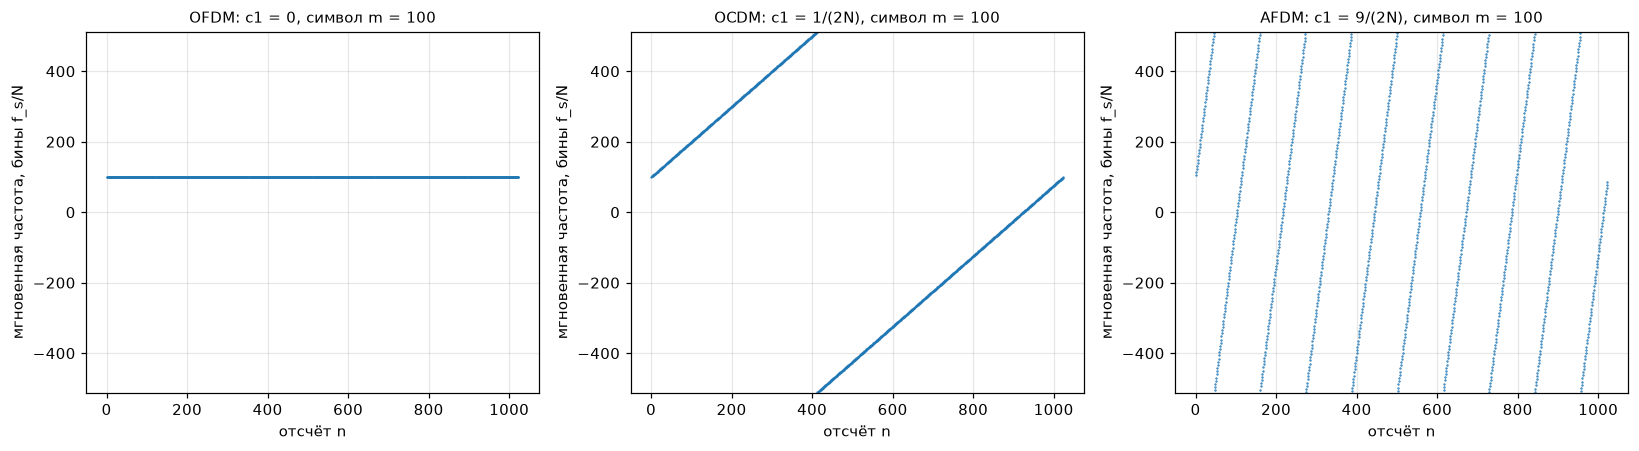

DAFT с c1 = c2 = 1/(2N) — это матрица Френеля Φ[m,n] = e^(−jπ/4)·e^(jπ(m−n)²/N)/√N с отражённым индексом и общей фазой: разброс фазы 1.3e-12
Ортогональность чирпов AFDM: max|⟨φ_m, φ_k⟩ − δ| = 5.0e-16; наклон (скорость изменения частоты) 2c1·N = 9.0000 бина на отсчёт


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
m0 = 100
for a, (c1, name) in zip(ax, ((0.0, "OFDM: c1 = 0"), (1 / (2 * N), "OCDM: c1 = 1/(2N)"), (C1_OPT, f"AFDM: c1 = {2*N*C1_OPT:.0f}/(2N)"))):
    e = np.zeros(N, complex); e[m0] = 1
    s = modulate(e[None], c1, cp=0)[0]
    inst = np.diff(np.unwrap(np.angle(s))) / (2 * np.pi) * N       # мгновенная частота в бинах f_s/N
    a.plot(n_[1:], (inst + N / 2) % N - N / 2, ".", ms=1)
    a.set_xlabel("отсчёт n"); a.set_ylabel("мгновенная частота, бины f_s/N"); a.set_title(f"{name}, символ m = {m0}", fontsize=10)
    a.set_ylim(-N / 2, N / 2)
plt.tight_layout(); plt.show()

A1 = daft(1 / (2 * N), 1 / (2 * N))
m, nn = np.meshgrid(n_, n_, indexing="ij")
fresnel = np.exp(-1j * np.pi / 4) / np.sqrt(N) * np.exp(1j * np.pi * (m - nn)**2 / N)
ph = A1.conj() / fresnel[:, (-n_) % N]                      # A[m,n] ∝ e^(−jπ(m+n)²/N): Френель с отражённым индексом n → −n
print(f"DAFT с c1 = c2 = 1/(2N) — это матрица Френеля Φ[m,n] = e^(−jπ/4)·e^(jπ(m−n)²/N)/√N с отражённым индексом и общей фазой: разброс фазы {np.ptp(np.angle(ph / ph[0, 0])):.1e}")
G = daft(C1_OPT).conj().T
print(f"Ортогональность чирпов AFDM: max|⟨φ_m, φ_k⟩ − δ| = {np.max(np.abs(G.conj().T @ G - np.eye(N))):.1e}; наклон (скорость изменения частоты) 2c1·N = {2*C1_OPT*N:.4f} бина на отсчёт")

## 2. Чирп-периодический префикс (CPP)
OFDM нужен CP, чтобы линейная свёртка с каналом стала циклической. Для этого сигнал должен быть периодичен: $s[n-N]=s[n]$. Чирп $e^{j2\pi c_1n^2}$ сам по себе не периодичен с периодом $N$: при сдвиге на $N$ появляется множитель $e^{-j2\pi c_1(N^2+2Nn)}$. Поэтому AFDM использует **чирп-периодический префикс**
$$s[n]=s[N+n]\,e^{-j2\pi c_1(N^2+2Nn)},\qquad n=-L_\text{cp}\dots-1 .$$
При целом $2Nc_1$ и чётном $N$ множитель равен 1, и CPP совпадает с обычным CP (наш основной случай, $2Nc_1=9$). При дробном $2Nc_1$ обычный CP ломает модель: ошибка ~2 %, то есть пол SINR около −33 дБ, а CPP точен до машинной точности.

При целом 2N·c1 и чётном N множитель CPP e^(−j2πc1(N²+2Nn)) = 1, и CPP совпадает с обычным CP (наш случай, 2N·c1 = 9). Возьмём дробное 2N·c1:


  2N·c1 = 9.37, CPP         : ошибка модели y = H_eff·x: 1.2e-15
  2N·c1 = 9.37, обычный CP  : ошибка модели y = H_eff·x: 2.2e-02


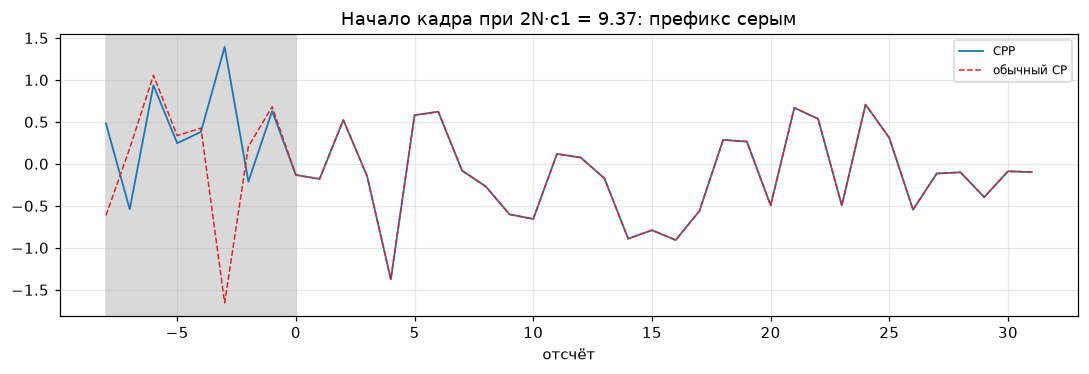

In [4]:
pth = draw_paths(np.random.default_rng(3), integer=True)
_, x = qpsk_bits(1, N, rng)
print(f"При целом 2N·c1 и чётном N множитель CPP e^(−j2πc1(N²+2Nn)) = 1, и CPP совпадает с обычным CP (наш случай, 2N·c1 = {2*N*C1_OPT:.0f}). Возьмём дробное 2N·c1:")
c1f = C1_OPT + 0.37 / (2 * N)
H = eff_matrix(pth, c1f)
s_cpp = modulate(x, c1f)
s_cp = s_cpp.copy(); s_cp[:, :L_CP] = s_cpp[:, N:N + L_CP]                  # обычный CP: копия хвоста без чирп-поправки
for s, name in ((s_cpp, "CPP"), (s_cp, "обычный CP")):
    y = demodulate(channel(s, pth), c1f)
    print(f"  2N·c1 = {2*N*c1f:.2f}, {name:12}: ошибка модели y = H_eff·x: {np.linalg.norm(y - x @ H.T)/np.linalg.norm(y):.1e}")
fig, a = plt.subplots(figsize=(10, 3.5))
t = np.arange(-L_CP, N)
a.plot(t[:40], s_cpp[0, :40].real, "C0", lw=1.2, label="CPP")
a.plot(t[:40], s_cp[0, :40].real, "C3--", lw=1, label="обычный CP")
a.axvspan(-L_CP, 0, color="0.85"); a.set_xlabel("отсчёт"); a.legend(fontsize=8)
a.set_title(f"Начало кадра при 2N·c1 = {2*N*c1f:.2f}: префикс серым")
plt.tight_layout(); plt.show()

## 3. Канал в области DAFT
Один и тот же канал (5 лучей, целый доплер), столбец эффективной матрицы $H_\text{eff}=AH_\text{time}A^H$ — куда уходит один символ:
- **OFDM** ($c_1=0$): сдвиг $=\alpha$. Задержка вообще не сдвигает, все лучи с одинаковым доплером **складываются** в один отсчёт (здесь два луча с $\alpha=+1$ слились: 4 ненулевых вместо 5). Это потеря разнесения;
- **OCDM** ($2Nc_1=1$): сдвиг $=\alpha-l$. Задержка и доплер связаны, и лучи с одинаковым $\alpha-l$ сливаются. В этой реализации повезло, но в общем случае — нет;
- **AFDM** ($2Nc_1=9$): сдвиг $=\alpha-9l$. Каждой задержке достаётся своё окно из 9 отсчётов, в которое помещается весь диапазон доплеров $|\alpha|\le\alpha_\max+\xi=4$. Слияний **не бывает**.

Условие на кадр: $(\alpha_\max+\xi)(2l_\max+1)+l_\max<N$, то есть все окна должны поместиться в $N$ отсчётов. Здесь 40 из 1024: огромный запас.

OFDM, c1 = 0          : ненулевых в столбце    4; позиции лучей (l=0, α=+1) → +1, (l=1, α=+1) → +1, (l=2, α=-2) → -2, (l=3, α=+0) → +0, (l=4, α=+2) → +2


OCDM, c1 = 1/(2N)     : ненулевых в столбце    5; позиции лучей (l=0, α=+1) → +1, (l=1, α=+1) → +0, (l=2, α=-2) → -4, (l=3, α=+0) → -3, (l=4, α=+2) → -2


AFDM, c1 = 9/(2N)     : ненулевых в столбце    5; позиции лучей (l=0, α=+1) → +1, (l=1, α=+1) → -8, (l=2, α=-2) → -20, (l=3, α=+0) → -27, (l=4, α=+2) → -34


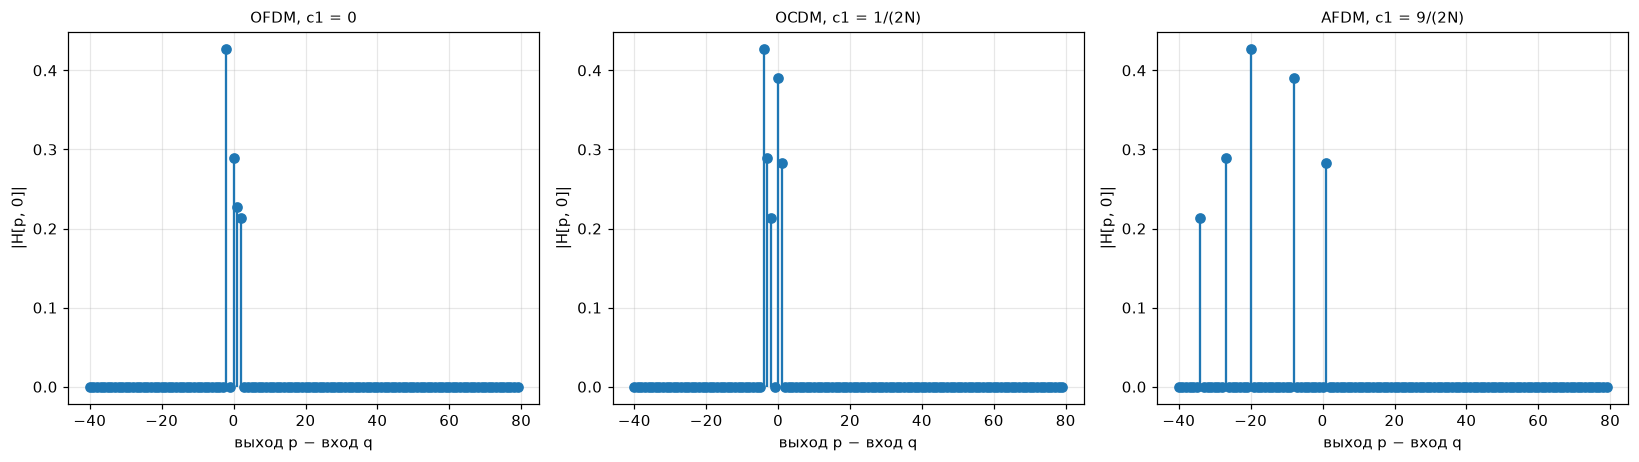

Формула AFDM: луч (l, α) сдвигает символ на (α − 2N·c1·l) mod N (знак — из нашего соглашения e^(+j2πνt)); при c1 = 9/(2N) это α − 9·l: разные задержки не перекрываются, пока |α| ≤ α_max + ξ


In [5]:
pth = draw_paths(np.random.default_rng(5), integer=True)
cases = {"OFDM, c1 = 0": 0.0, "OCDM, c1 = 1/(2N)": 1 / (2 * N), f"AFDM, c1 = {2*N*C1_OPT:.0f}/(2N)": C1_OPT}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, (name, c1) in zip(ax, cases.items()):
    H = eff_matrix(pth, c1)
    col = np.abs(H[:, 0]); col = np.roll(col, 40)
    a.stem(np.arange(-40, 80), col[:120], basefmt=" ")
    a.set_xlabel("выход p − вход q"); a.set_ylabel("|H[p, 0]|"); a.set_title(name, fontsize=10)
    nz = np.sum(np.abs(H[:, 0]) > 1e-6)
    print(f"{name:22}: ненулевых в столбце {nz:4d}; позиции лучей " +
          ", ".join(f"(l={l}, α={int(round(nu*N/FS)):+d}) → {int(np.argmax(np.abs(eff_matrix([(1, l, nu)], c1)[:, 0])) + N//2) % N - N//2:+d}" for h, l, nu in pth))
plt.tight_layout(); plt.show()
print(f"Формула AFDM: луч (l, α) сдвигает символ на (α − 2N·c1·l) mod N (знак — из нашего соглашения e^(+j2πνt)); при c1 = {2*N*C1_OPT:.0f}/(2N) это α − {2*N*C1_OPT:.0f}·l: разные задержки не перекрываются, пока |α| ≤ α_max + ξ")

## 4. BER: OFDM, OCDM, AFDM, OTFS на одном канале
QPSK без кода, LMMSE по полной матрице канала у всех четырёх. Значит, OFDM здесь уже без пола ICI (как «полный LMMSE» в разделе 4 `otfs_sim`), и разница — только в том, как форма волны распределяет символ по лучам. Дробный доплер, новый канал на каждый кадр.

- **OFDM** — самый пологий наклон: символ живёт на одной поднесущей, разнесение по задержкам ему недоступно.
- **OCDM** — круче, но слияния $\alpha-l$ отнимают часть разнесения.
- **AFDM** и **OTFS** — практически одна кривая. Обе формы волны разделяют все лучи и дают детектору полное разнесение.

Итог Bemani et al. подтверждается: AFDM по BER не уступает OTFS, при этом кадр одномерный, а модем — это OFDM-модем с двумя диагональными умножениями на чирпы.

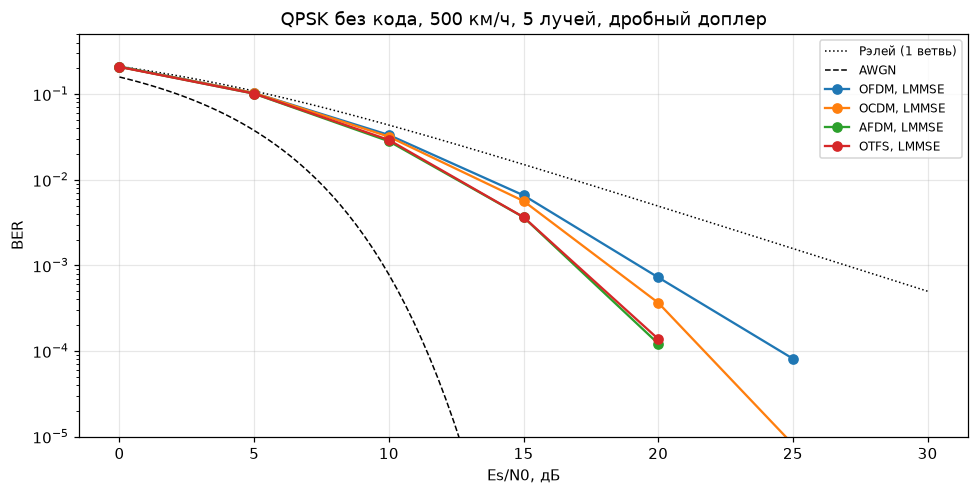

30 каналов за 88 с
OFDM : BER при 15 / 20 / 25 дБ = 6.6e-03 / 7.2e-04 / 8.1e-05
OCDM : BER при 15 / 20 / 25 дБ = 5.6e-03 / 3.7e-04 / 8.1e-06
AFDM : BER при 15 / 20 / 25 дБ = 3.7e-03 / 1.2e-04 / 0.0e+00
OTFS : BER при 15 / 20 / 25 дБ = 3.7e-03 / 1.4e-04 / 0.0e+00


In [6]:
# OTFS 64×16 на том же канале (минимальный модем из otfs_sim)
Mo, No = 64, 16
def otfs_mod(x, cp=L_CP):
    s = (np.fft.ifft(x.reshape(x.shape[:-1] + (Mo, No)), axis=-1) * np.sqrt(No)).swapaxes(-1, -2).reshape(x.shape)
    return np.concatenate([s[..., -cp:], s], -1)
def otfs_demod(r, cp=L_CP):
    Y = r[..., cp:cp + N].reshape(r.shape[:-1] + (No, Mo)).swapaxes(-1, -2)
    return (np.fft.fft(Y, axis=-1) / np.sqrt(No)).reshape(r.shape[:-1] + (N,))
def eff_otfs(paths):
    return otfs_demod(channel(otfs_mod(np.eye(N, dtype=complex)), paths)).T

snrs = np.arange(0, 31, 5)
schemes = {"OFDM": 0.0, "OCDM": 1 / (2 * N), "AFDM": C1_OPT, "OTFS": None}
ber = {k: np.zeros(len(snrs)) for k in schemes}
t0 = time.time()
for f in range(FRAMES):
    pth = draw_paths(rng)
    for k, c1 in schemes.items():
        H = eff_otfs(pth) if c1 is None else eff_matrix(pth, c1)
        b, x = qpsk_bits(2, N, rng)
        for i, snr in enumerate(snrs):
            n0 = 10 ** (-snr / 10)
            y = x @ H.T + np.sqrt(n0) * crandn(x.shape, rng)
            ber[k][i] += np.mean(hard_bits(lmmse(H, y, n0)) != b)
ber = {k: v / FRAMES for k, v in ber.items()}
fig, a = plt.subplots(figsize=(9, 4.6))
sg = np.linspace(0, 30, 100); gg = 10 ** (sg / 10)
a.semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Рэлей (1 ветвь)")
a.semilogy(sg, 0.5 * erfc(np.sqrt(gg / 2)), "k--", lw=1, label="AWGN")
for i, k in enumerate(schemes):
    ok = ber[k] > 0
    a.semilogy(snrs[ok], ber[k][ok], f"C{i}o-", label=f"{k}, LMMSE")
a.set_ylim(1e-5, 0.5); a.set_xlabel("Es/N0, дБ"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"QPSK без кода, {SPEED_KMH} км/ч, {P_PATHS} лучей, дробный доплер")
plt.tight_layout(); plt.show()
print(f"{FRAMES} каналов за {time.time()-t0:.0f} с")
for k in schemes:
    print(f"{k:5}: BER при 15 / 20 / 25 дБ = {ber[k][3]:.1e} / {ber[k][4]:.1e} / {ber[k][5]:.1e}")

## 5. Встроенный пилот в одномерном кадре
Один пилот в позиции 0. Его отклик — окна по 9 отсчётов на каждую задержку, в сумме $2Nc_1l_\max+2(\alpha_\max+\xi)+1$ отсчётов. Защита — это они плюс столько же с другой стороны, чтобы данные туда не затекали: 89 символов из 1024, **8.7 %** (у OTFS в `otfs_sim` защита — целые строки задержек на все доплеры, 14 %). Приёмник для каждой задержки $l$ и доплера $\alpha$ в окне берёт отсчёт $y[\alpha-9l]$ и, если он выше $3\sigma$, добавляет «виртуальный» луч $(l,\alpha)$ с этим коэффициентом.

- **Целый доплер**: оценка практически идеальна, BER совпадает с точным CSI.
- **Дробный доплер**: каждый луч расплывается по окну ядром Дирихле (запас $\xi=2$ как раз для этого), модель «целых лучей» неточна, и BER упирается в пол ~$4\cdot10^{-2}$. Это та же проблема, что у OTFS 1.0 (раздел 5 `otfs_sim`). В литературе её решают оценкой дробной части доплера (поиск по сетке, ML) или большим $\xi$. Zak-OTFS (`zak_sim`) решает её выбором импульса.

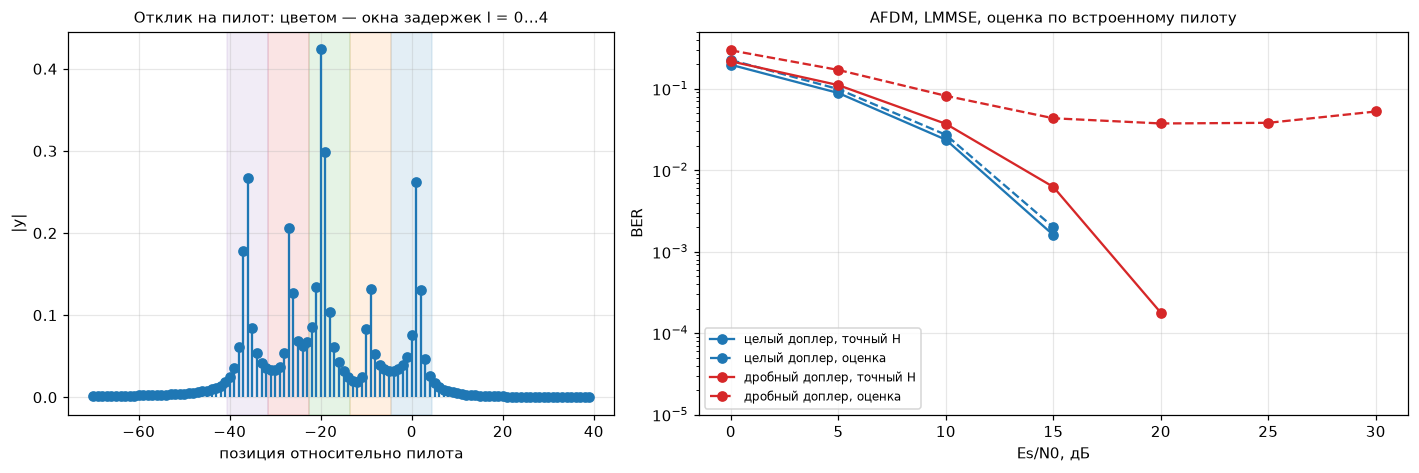

Защита AFDM: 89 из 1024 символов = 8.7% (у OTFS в otfs_sim — 14 %); пилот +19.5 дБ
  SNR  0: int_true 2.0e-01  int_est 2.3e-01  frac_true 2.2e-01  frac_est 3.0e-01
  SNR  5: int_true 8.9e-02  int_est 9.9e-02  frac_true 1.1e-01  frac_est 1.7e-01
  SNR 10: int_true 2.4e-02  int_est 2.7e-02  frac_true 3.7e-02  frac_est 8.2e-02
  SNR 15: int_true 1.6e-03  int_est 2.0e-03  frac_true 6.2e-03  frac_est 4.3e-02
  SNR 20: int_true 0.0e+00  int_est 0.0e+00  frac_true 1.8e-04  frac_est 3.7e-02
  SNR 25: int_true 0.0e+00  int_est 0.0e+00  frac_true 0.0e+00  frac_est 3.8e-02
  SNR 30: int_true 0.0e+00  int_est 0.0e+00  frac_true 0.0e+00  frac_est 5.3e-02


In [7]:
# встроенный пилот в одномерном кадре AFDM (Bemani et al.)
Q = A_MAX + XI
PILOT = 0
G = 2 * N * C1_OPT                                            # сдвиг на отсчёт задержки
guard = np.zeros(N, bool)
span = int(G * L_MAX + Q)                                     # отклик пилота: позиции −span … Q
guard[(PILOT + np.arange(-span - Q, span + Q + 1)) % N] = True
DATA = ~guard; XP = np.sqrt(guard.sum())

def estimate(y, n0, thr=3.0):
    """Для каждой задержки l читаем окно доплеров α ∈ [−Q, Q] у позиции PILOT + α − G·l и строим H из «виртуальных» лучей (l, α) выше порога."""
    He = np.zeros((N, N), complex)
    for l in range(L_MAX + 1):
        for al in range(-Q, Q + 1):
            pos = int(PILOT + al - G * l) % N
            if abs(y[pos]) > thr * np.sqrt(n0):
                Hb = BASIS[(l, al)]
                He += y[pos] / (XP * Hb[pos, PILOT]) * Hb
    return He

BASIS = {(l, al): eff_matrix([(1.0, l, al * FS / N)], C1_OPT) for l in range(L_MAX + 1) for al in range(-Q, Q + 1)}
snrs5 = np.arange(0, 31, 5)
r5 = {k: np.zeros(len(snrs5)) for k in ("int_true", "int_est", "frac_true", "frac_est")}
for f in range(FRAMES // 2):
    for integer, tag in ((True, "int"), (False, "frac")):
        pth = draw_paths(rng, integer); H = eff_matrix(pth, C1_OPT)
        b, xd = qpsk_bits(1, N, rng); x = xd[0] * DATA; x[PILOT] = XP
        for i, snr in enumerate(snrs5):
            n0 = 10 ** (-snr / 10); y = H @ x + np.sqrt(n0) * crandn(N, rng)
            He = estimate(y, n0)
            for Hd, kk in ((H, "true"), (He, "est")):
                z = lmmse(Hd[:, DATA], (y - Hd[:, PILOT] * XP)[None], n0)[0]
                r5[f"{tag}_{kk}"][i] += np.mean(hard_bits(z) != b[0, DATA])
r5 = {k: v / (FRAMES // 2) for k, v in r5.items()}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
pth = draw_paths(np.random.default_rng(9)); H = eff_matrix(pth, C1_OPT)
e = np.zeros(N, complex); e[PILOT] = 1
resp = np.abs(np.roll(H @ e, span + 30))[:span + 30 + 40]
ax[0].stem(np.arange(-span - 30, 40), resp, basefmt=" ")
for l in range(L_MAX + 1):
    ax[0].axvspan(-G * l - Q - 0.5, -G * l + Q + 0.5, color=f"C{l}", alpha=0.12)
ax[0].set_xlabel("позиция относительно пилота"); ax[0].set_ylabel("|y|")
ax[0].set_title(f"Отклик на пилот: цветом — окна задержек l = 0…{L_MAX}", fontsize=10)
for k, c, ls, lab in (("int_true", "C0", "-", "целый доплер, точный H"), ("int_est", "C0", "--", "целый доплер, оценка"),
                      ("frac_true", "C3", "-", "дробный доплер, точный H"), ("frac_est", "C3", "--", "дробный доплер, оценка")):
    ok = r5[k] > 0
    ax[1].semilogy(snrs5[ok], r5[k][ok], c + "o", ls=ls, label=lab)
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlabel("Es/N0, дБ"); ax[1].set_ylabel("BER"); ax[1].legend(fontsize=8)
ax[1].set_title("AFDM, LMMSE, оценка по встроенному пилоту", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Защита AFDM: {guard.sum()} из {N} символов = {guard.mean():.1%} (у OTFS в otfs_sim — 14 %); пилот +{10*np.log10(XP**2):.1f} дБ")
for i, snr in enumerate(snrs5):
    print(f"  SNR {snr:2d}: " + "  ".join(f"{k} {v[i]:.1e}" for k, v in r5.items()))

## Сравнение: OFDM, OCDM, AFDM, OTFS
| | OFDM | OCDM | AFDM | OTFS |
|---|---|---|---|---|
| Базис | тоны | чирпы, наклон 1/N | чирпы, наклон $2c_1$ под доплер | DD-решётка $M\times N$ |
| Кадр | 1D, $N$ | 1D, $N$ | 1D, $N$ | 2D, $M\times N$ |
| Модем | IFFT | $F^H\Gamma F$ | $\Lambda_{c_1}^HF^H\Lambda_{c_2}^H$ — OFDM + 2 диагонали | ISFFT + OFDM |
| Сдвиг луча $(l,\alpha)$ | $\alpha$ | $\alpha-l$ | $\alpha-2Nc_1l$ | $(l,\alpha)$ на решётке |
| Разнесение (LMMSE/MP) | 1 по символу | частичное | полное | полное |
| Префикс | CP на символ | CP | CPP (= CP при целом $2Nc_1$) | CP на кадр |
| Защита для пилота (здесь) | — | — | 8.7 % | 14 % |
| Дробный доплер | ICI | ICI | пол оценки, лечится $\xi$ | пол оценки (Zak-OTFS — нет) |
| Совместимость с OFDM | — | высокая | высокая: те же FFT | прекодер поверх |

AFDM интересна как эволюционный путь: модем — это OFDM с двумя дополнительными диагональными умножениями, а $c_1$ — параметр, который можно менять от кадра к кадру под скорость. При $c_1=0$ это снова OFDM. Последний ноутбук серии, **OTSM/ODDM**, разбирает другой путь упрощения — одну несущую в DD.

## Что покрутить
- `XI = 0` — $c_1$ меньше, окна задержек уже. Целый доплер не страдает, а дробный в разделе 5 перетекает между окнами, и пол оценки поднимается
- `SPEED_KMH = 1500` — $\alpha_\max=6$, $c_1$ растёт автоматически ($2Nc_1=17$); AFDM и OTFS в разделе 4 по-прежнему вместе
- `P_PATHS = 2` — разнесения меньше: все четыре кривые сближаются
- в разделе 4 добавить схему с $c_1$ меньше оптимального (например `"AFDM-": 3 / (2 * N)`) — окна перекрываются, и наклон падает до уровня OCDM
- в разделе 2 поставить `c1f = C1_OPT` — обычный CP снова точен, потому что $2Nc_1$ целое